In [1]:
# Thiết lập môi trường làm việc (tự động phát hiện Google Colab hoặc Local)
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    colab_dir = "/content/drive/MyDrive/ColabNotebooks/Noron&DeepLearning/techtrail-ai-engine-v1"
    if os.path.exists(colab_dir):
        %cd {colab_dir}
except Exception:
    pass

print("Đường dẫn làm việc hiện tại:", os.getcwd())
print("Danh sách file trong data/:", os.listdir('data') if os.path.exists('data') else "Chưa có thư mục data")


Đường dẫn làm việc hiện tại: d:\coding\My AI project\techtrail-ai-engine-v1
Danh sách file trong data/: ['resume-dataset.csv', 'test.csv', 'train.csv', 'val.csv']


## Chia data thành 70-15-15: train-test-validation


In [2]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

os.makedirs("data", exist_ok=True)

train_path = "data/train.csv"
val_path = "data/val.csv"
test_path = "data/test.csv"

# Cờ FORCE_RE_SPLIT: Đặt True để ép buộc chia lại từ dataset gốc mới nhất; False: ưu tiên đọc file đã chia sẵn
FORCE_RE_SPLIT = True

splits_exist = (
    os.path.exists(train_path) and os.path.getsize(train_path) > 0 and
    os.path.exists(val_path) and os.path.getsize(val_path) > 0 and
    os.path.exists(test_path) and os.path.getsize(test_path) > 0
)

if splits_exist and not FORCE_RE_SPLIT:
    print("Phát hiện các file train.csv, val.csv, test.csv đã có sẵn trong data/. Đang tải...")
    train_df = pd.read_csv(train_path)
    val_df = pd.read_csv(val_path)
    test_df = pd.read_csv(test_path)
    
    # Chuẩn hóa bảng ánh xạ Category <-> Label ID từ dữ liệu có sẵn
    if 'category' in train_df.columns and 'label' in train_df.columns:
        cat_label_df = train_df[['category', 'label']].drop_duplicates().sort_values('label')
        category_to_id = dict(zip(cat_label_df['category'], cat_label_df['label']))
        id_to_category = dict(zip(cat_label_df['label'], cat_label_df['category']))
    else:
        unique_categories = sorted(train_df['category'].unique())
        category_to_id = {cat: idx for idx, cat in enumerate(unique_categories)}
        id_to_category = {idx: cat for cat, idx in category_to_id.items()}
        train_df['label'] = train_df['category'].map(category_to_id)
        val_df['label'] = val_df['category'].map(category_to_id)
        test_df['label'] = test_df['category'].map(category_to_id)
    
    print("Đã tải thành công dữ liệu từ các file có sẵn!")

else:
    print("Tiến hành nạp và phân chia lại từ dataset gốc mới nhất (FORCE_RE_SPLIT=True)...\n")
    
    # 1. Nạp file dataset gốc từ thư mục data/
    data_file = 'data/resume-dataset.csv'
    if not (os.path.exists(data_file) and os.path.getsize(data_file) > 0):
        other_csvs = [
            os.path.join('data', f) for f in os.listdir('data')
            if f.endswith('.csv') and not f.startswith(('train', 'val', 'test'))
        ]
        if other_csvs:
            data_file = other_csvs[0]
        else:
            raise FileNotFoundError("Không tìm thấy file dataset gốc nào trong thư mục data/!")

    print(f"Đang đọc dữ liệu từ: {data_file}")
    df = pd.read_csv(data_file)
    print(f"Đã tải {len(df)} dòng dữ liệu từ {data_file}")

    # 2. Chuẩn hóa tên cột
    text_col = None
    for col in ['Resume', 'text_sequence', 'clean_text', 'text', 'resume']:
        if col in df.columns:
            text_col = col
            break
    if text_col is None:
        raise KeyError(f"Không tìm thấy cột văn bản trong các cột: {df.columns.tolist()}")

    cat_col = None
    for col in ['Category', 'category', 'label']:
        if col in df.columns:
            cat_col = col
            break
    if cat_col is None:
        raise KeyError(f"Không tìm thấy cột ngành nghề trong các cột: {df.columns.tolist()}")

    # Ánh xạ nhãn Category thành số nguyên (0..N-1)
    unique_categories = sorted(df[cat_col].unique())
    category_to_id = {cat: idx for idx, cat in enumerate(unique_categories)}
    id_to_category = {idx: cat for cat, idx in category_to_id.items()}

    df['text_sequence'] = df[text_col].astype(str)
    df['category'] = df[cat_col]
    df['label'] = df['category'].map(category_to_id)
    if 'id' not in df.columns:
        df['id'] = df.index
    df = df[['id', 'text_sequence', 'category', 'label']]

    # 3. Chia 70-15-15: train-val-test phân tầng theo nhãn
    train_df, temp_df = train_test_split(df, test_size=0.30, random_state=42, stratify=df['label'])
    val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df['label'])

    train_df = train_df.reset_index(drop=True)
    val_df = val_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    # Lưu ra file CSV
    train_df.to_csv(train_path, index=False)
    val_df.to_csv(val_path, index=False)
    test_df.to_csv(test_path, index=False)
    print("Đã lưu các file train.csv, val.csv, test.csv vào thư mục data/.")

# 4. In thông tin tổng kết
total_len = len(train_df) + len(val_df) + len(test_df)
print(f"\nKích thước các tập dữ liệu:")
print(f"  Train: {len(train_df)} dòng ({len(train_df)/total_len*100:.1f}%)")
print(f"  Val:   {len(val_df)} dòng ({len(val_df)/total_len*100:.1f}%)")
print(f"  Test:  {len(test_df)} dòng ({len(test_df)/total_len*100:.1f}%)")

print("\nBảng ánh xạ nhãn (Category -> Label ID):")
for cat, idx in sorted(category_to_id.items(), key=lambda x: x[1]):
    print(f"  {idx}: {cat}")


Tiến hành nạp và phân chia lại từ dataset gốc mới nhất (FORCE_RE_SPLIT=True)...

Đang đọc dữ liệu từ: data/resume-dataset.csv
Đã tải 2000 dòng dữ liệu từ data/resume-dataset.csv
Đã lưu các file train.csv, val.csv, test.csv vào thư mục data/.

Kích thước các tập dữ liệu:
  Train: 1400 dòng (70.0%)
  Val:   300 dòng (15.0%)
  Test:  300 dòng (15.0%)

Bảng ánh xạ nhãn (Category -> Label ID):
  0: Backend Developer
  1: Cloud Enginee
  2: Data Scientist
  3: Frontend Developer
  4: Full Stack Developer
  5: Machine Learning Engineer
  6: Mobile App Developer (iOS/Android)
  7: Python Developer


## Hàm cắt văn bản thành chuỗi thời gian

In [3]:
def split_into_time_steps(text, num_steps=3):
    words = str(text).split()
    if len(words) == 0:
        return [""] * num_steps

    chunk_size = max(1, len(words) // num_steps)
    chunks = []

    for i in range(num_steps):
        if i == num_steps - 1:
            chunk = words[i * chunk_size:]
        else:
            chunk = words[i * chunk_size : (i + 1) * chunk_size]
        chunks.append(" ".join(chunk))

    return chunks

## DataLoader biến chữ thành mảng số

In [4]:
import torch
from torch.utils.data import Dataset, DataLoader

class TechTrailDataset(Dataset):
    def __init__(self, dataframe, vocab, max_seq_length, num_steps=3):
        self.data = dataframe.reset_index(drop=True)
        self.vocab = vocab
        self.max_len = max_seq_length
        self.num_steps = num_steps

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        text = str(row['text_sequence'])
        label = int(row['label'])

        time_steps = split_into_time_steps(text, self.num_steps)

        sequence_tensor = torch.zeros((self.num_steps, self.max_len), dtype=torch.long)

        for step_idx, step_text in enumerate(time_steps):
            tokens = step_text.split()
            token_ids = [self.vocab.get(word, self.vocab.get('<UNK>', 1)) for word in tokens]

            if len(token_ids) > self.max_len:
                token_ids = token_ids[:self.max_len]
            else:
                token_ids = token_ids + [self.vocab.get('<PAD>', 0)] * (self.max_len - len(token_ids))

            sequence_tensor[step_idx] = torch.tensor(token_ids, dtype=torch.long)

        return sequence_tensor, torch.tensor(label, dtype=torch.long)

In [5]:
from collections import Counter

# 1. Xây dựng từ điển vocab từ tập train
def build_vocab(texts, min_freq=1):
    word_counts = Counter()
    for text in texts:
        word_counts.update(str(text).split())
    vocab = {'<PAD>': 0, '<UNK>': 1}
    for word, count in word_counts.items():
        if count >= min_freq and word not in vocab:
            vocab[word] = len(vocab)
    return vocab

vocab = build_vocab(train_df['text_sequence'])
print(f"Kích thước từ điển (Vocab size): {len(vocab)} từ")

# 2. Khởi tạo Dataset và DataLoader cho cả 3 tập train, val, test
max_seq_length = 50
batch_size = 32

train_dataset = TechTrailDataset(train_df, vocab, max_seq_length=max_seq_length, num_steps=3)
val_dataset = TechTrailDataset(val_df, vocab, max_seq_length=max_seq_length, num_steps=3)
test_dataset = TechTrailDataset(test_df, vocab, max_seq_length=max_seq_length, num_steps=3)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# 3. Kiểm tra thử 1 batch từ train_loader
for batch_x, batch_y in train_loader:
    print("\nKiểm tra 1 batch từ DataLoader thành công:")
    print("  Batch X shape (batch_size, num_steps, max_seq_length):", batch_x.shape)
    print("  Batch Y shape (batch_size):", batch_y.shape)
    print("  Nhãn số trong batch:", batch_y[:8].tolist())
    print("  Tên ngành nghề tương ứng:", [id_to_category[y.item()] for y in batch_y[:8]])
    break

Kích thước từ điển (Vocab size): 1649 từ

Kiểm tra 1 batch từ DataLoader thành công:
  Batch X shape (batch_size, num_steps, max_seq_length): torch.Size([32, 3, 50])
  Batch Y shape (batch_size): torch.Size([32])
  Nhãn số trong batch: [6, 3, 0, 0, 2, 0, 2, 1]
  Tên ngành nghề tương ứng: ['Mobile App Developer (iOS/Android)', 'Frontend Developer', 'Backend Developer', 'Backend Developer', 'Data Scientist', 'Backend Developer', 'Data Scientist', 'Cloud Enginee']


## 1. Cài đặt Kiến trúc Mô hình RNN và LSTM

Mỗi phản hồi/hồ sơ của ứng viên được chia thành $T=3$ bước thời gian, mỗi bước chứa chuỗi từ (tối đa $L=50$ tokens).
- **Embedding Layer**: Mã hóa các token ID thành vector embedding (`embed_dim = 128`).
- **Masked Mean Pooling**: Tính vector đại diện từng bước phản hồi, bỏ qua token đệm `<PAD>`.
- **RNN / LSTM Layer**: Mô hình hóa sự phụ thuộc theo chuỗi thời gian qua các bước phản hồi.
- **Linear Classifier**: Phân loại ra 8 nhóm ngành nghề CNTT.

In [6]:
import torch
import torch.nn as nn

class TechTrailRNN(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128, num_classes=len(category_to_id), num_layers=1, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.dropout = nn.Dropout(dropout)
        self.rnn = nn.RNN(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            nonlinearity='tanh',
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x):
        # x: (batch_size, num_steps, max_len)
        embeds = self.embedding(x)  # (B, S, L, D)
        mask = (x != 0).unsqueeze(-1).float()  # (B, S, L, 1)
        sum_embeds = (embeds * mask).sum(dim=2)  # (B, S, D)
        lengths = mask.sum(dim=2).clamp(min=1e-9)
        step_features = self.dropout(sum_embeds / lengths)

        out, hn = self.rnn(step_features)
        last_hidden = hn[-1]  # (B, hidden_dim)
        logits = self.fc(last_hidden)
        return logits

class TechTrailLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128, num_classes=len(category_to_id), num_layers=1, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x):
        # x: (batch_size, num_steps, max_len)
        embeds = self.embedding(x)
        mask = (x != 0).unsqueeze(-1).float()
        sum_embeds = (embeds * mask).sum(dim=2)
        lengths = mask.sum(dim=2).clamp(min=1e-9)
        step_features = self.dropout(sum_embeds / lengths)

        out, (hn, cn) = self.lstm(step_features)
        last_hidden = hn[-1]
        logits = self.fc(last_hidden)
        return logits

# Khởi tạo thử mô hình LSTM
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
sample_model = TechTrailLSTM(vocab_size=len(vocab), embed_dim=128, hidden_dim=128, num_classes=len(category_to_id)).to(device)
print(f"Khởi tạo thành công mô hình TechTrailLSTM trên thiết bị: {device}")
total_params = sum(p.numel() for p in sample_model.parameters() if p.requires_grad)


Khởi tạo thành công mô hình TechTrailLSTM trên thiết bị: cuda


## 2. Thiết lập Loss Function, Optimizer & Vòng lặp Huấn luyện (Training Loop)

- **Loss Function**: `nn.CrossEntropyLoss()` (chuẩn hóa Softmax và tính Negative Log Likelihood Loss).
- **Optimizer**: `Adam(lr=0.002, weight_decay=1e-4)`.
- **Learning Rate Scheduler**: `ReduceLROnPlateau` tự động giảm tốc độ học khi hàm mất mát chững lại.
- **Early Stopping**: Tự động dừng huấn luyện khi Loss trên tập validation không cải thiện sau $N$ epochs, đồng thời lưu trọng số tốt nhất.

In [7]:
import os
import time
import numpy as np
import torch.optim as optim

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    for batch_x, batch_y in dataloader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        logits = model(batch_x)
        loss = criterion(logits, batch_y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()

        total_loss += loss.item() * batch_x.size(0)
        preds = logits.argmax(dim=1)
        total_correct += (preds == batch_y).sum().item()
        total_samples += batch_x.size(0)

    return total_loss / total_samples, total_correct / total_samples

def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch_x, batch_y in dataloader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            logits = model(batch_x)
            loss = criterion(logits, batch_y)

            total_loss += loss.item() * batch_x.size(0)
            preds = logits.argmax(dim=1)
            total_correct += (preds == batch_y).sum().item()
            total_samples += batch_x.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch_y.cpu().numpy())

    return total_loss / total_samples, total_correct / total_samples, np.array(all_preds), np.array(all_labels)

def train_model(model, train_loader, val_loader, epochs=15, lr=2e-3, patience=5, save_name='best_model.pt'):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
    os.makedirs('checkpoints', exist_ok=True)
    save_path = os.path.join('checkpoints', save_name)

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_val_loss = float('inf')
    patience_counter = 0

    print(f"Bắt đầu huấn luyện mô hình ({epochs} epochs tối đa)...")
    print("=" * 75)
    print(f"{'Epoch':<8} | {'Train Loss':<12} | {'Train Acc':<11} | {'Val Loss':<11} | {'Val Acc':<10} | {'Trạng thái'}")
    print("=" * 75)

    start_time = time.time()
    for epoch in range(1, epochs + 1):
        t_loss, t_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        v_loss, v_acc, _, _ = evaluate(model, val_loader, criterion, device)

        history['train_loss'].append(t_loss)
        history['train_acc'].append(t_acc)
        history['val_loss'].append(v_loss)
        history['val_acc'].append(v_acc)

        scheduler.step(v_loss)
        status = ""
        if v_loss < best_val_loss:
            best_val_loss = v_loss
            torch.save(model.state_dict(), save_path)
            status = "(*) Lưu model tốt nhất"
            patience_counter = 0
        else:
            patience_counter += 1

        print(f"{epoch:02d}/{epochs:02d}    | {t_loss:<12.4f} | {t_acc*100:<10.2f}% | {v_loss:<11.4f} | {v_acc*100:<9.2f}% | {status}")
        if patience_counter >= patience:
            print(f"\n[HỘI TỤ] Hàm mất mát không giảm thêm sau {patience} epochs liên tiếp. Dừng sớm tại Epoch {epoch}.")
            break

    elapsed = time.time() - start_time
    print("=" * 75)
    print(f"Hoàn thành huấn luyện trong: {elapsed:.2f} giây! Checkpoint đã lưu tại '{save_path}'")
    return history, save_path

## 3. Huấn luyện Mô hình LSTM cho đến khi Loss hội tụ

In [8]:
# Khởi tạo mô hình TechTrailLSTM
lstm_model = TechTrailLSTM(
    vocab_size=len(vocab),
    embed_dim=128,
    hidden_dim=128,
    num_classes=len(category_to_id),
    dropout=0.3
).to(device)

# Chạy huấn luyện đến khi hội tụ
lstm_history, best_lstm_ckpt = train_model(
    lstm_model,
    train_loader,
    val_loader,
    epochs=15,
    lr=0.002,
    patience=5,
    save_name='best_lstm_model.pt'
)

Bắt đầu huấn luyện mô hình (15 epochs tối đa)...
Epoch    | Train Loss   | Train Acc   | Val Loss    | Val Acc    | Trạng thái
01/15    | 2.0409       | 20.21     % | 1.8772      | 60.00    % | (*) Lưu model tốt nhất
02/15    | 1.1546       | 62.79     % | 0.5762      | 82.67    % | (*) Lưu model tốt nhất
03/15    | 0.4544       | 83.29     % | 0.3078      | 87.33    % | (*) Lưu model tốt nhất
04/15    | 0.3115       | 88.57     % | 0.2104      | 92.00    % | (*) Lưu model tốt nhất
05/15    | 0.1899       | 94.14     % | 0.1915      | 92.67    % | (*) Lưu model tốt nhất
06/15    | 0.1265       | 96.00     % | 0.1682      | 93.67    % | (*) Lưu model tốt nhất
07/15    | 0.0976       | 96.64     % | 0.1333      | 96.33    % | (*) Lưu model tốt nhất
08/15    | 0.1069       | 96.64     % | 0.0918      | 96.67    % | (*) Lưu model tốt nhất
09/15    | 0.0499       | 98.43     % | 0.0719      | 97.00    % | (*) Lưu model tốt nhất
10/15    | 0.0476       | 98.57     % | 0.0733      | 96.67    

## 4. Trực quan hóa Quá trình Hội tụ của Loss và Accuracy

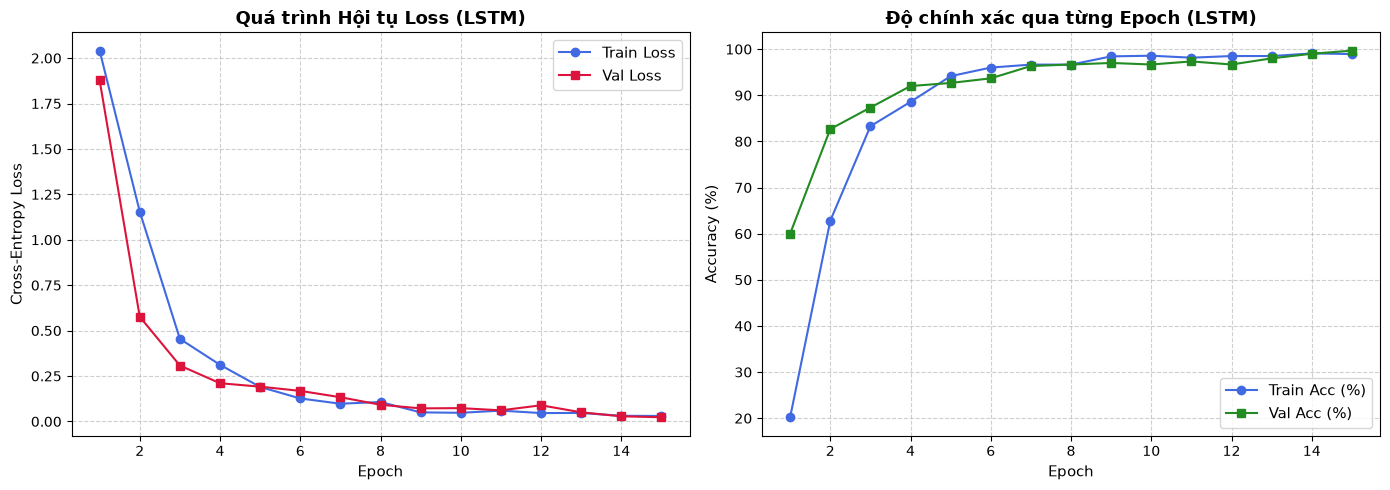

In [9]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(lstm_history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Biểu đồ Loss
axes[0].plot(epochs_range, lstm_history['train_loss'], label='Train Loss', color='royalblue', marker='o')
axes[0].plot(epochs_range, lstm_history['val_loss'], label='Val Loss', color='crimson', marker='s')
axes[0].set_title('Quá trình Hội tụ Loss (LSTM)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Cross-Entropy Loss', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=11)

# 2. Biểu đồ Accuracy
axes[1].plot(epochs_range, [acc * 100 for acc in lstm_history['train_acc']], label='Train Acc (%)', color='royalblue', marker='o')
axes[1].plot(epochs_range, [acc * 100 for acc in lstm_history['val_acc']], label='Val Acc (%)', color='forestgreen', marker='s')
axes[1].set_title('Độ chính xác qua từng Epoch (LSTM)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Accuracy (%)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(fontsize=11)

plt.tight_layout()
plt.savefig('checkpoints/lstm_training_curves.png', dpi=300)
plt.show()

## 5. Đánh giá Mô hình trên Tập Test và Log Kết quả Ban đầu


=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (300 mẫu) ===
Loss tập Test: 0.0330
Độ chính xác tập Test (Test Accuracy): 99.33%

--- BÁO CÁO PHÂN LOẠI CHI TIẾT (Classification Report) ---
                                    precision    recall  f1-score   support

                 Backend Developer     0.9737    1.0000    0.9867        37
                     Cloud Enginee     1.0000    1.0000    1.0000        37
                    Data Scientist     0.9744    1.0000    0.9870        38
                Frontend Developer     1.0000    1.0000    1.0000        38
              Full Stack Developer     1.0000    0.9737    0.9867        38
         Machine Learning Engineer     1.0000    1.0000    1.0000        37
Mobile App Developer (iOS/Android)     1.0000    1.0000    1.0000        38
                  Python Developer     1.0000    0.9730    0.9863        37

                          accuracy                         0.9933       300
                         macro avg     0.9935    0.9933    0

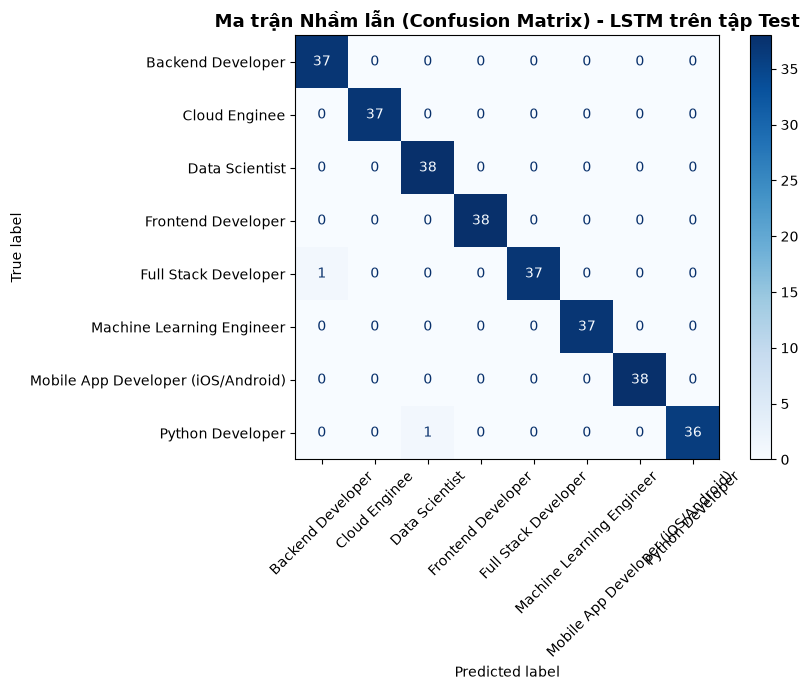

In [10]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Tải trọng số tốt nhất
lstm_model.load_state_dict(torch.load(best_lstm_ckpt))
criterion = nn.CrossEntropyLoss()
test_loss, test_acc, test_preds, test_labels = evaluate(lstm_model, test_loader, criterion, device)

print(f"\n=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ({len(test_loader.dataset)} mẫu) ===")
print(f"Loss tập Test: {test_loss:.4f}")
print(f"Độ chính xác tập Test (Test Accuracy): {test_acc * 100:.2f}%")

target_names = [id_to_category[i] for i in range(len(category_to_id))]
print("\n--- BÁO CÁO PHÂN LOẠI CHI TIẾT (Classification Report) ---")
print(classification_report(test_labels, test_preds, target_names=target_names, digits=4))

# Trực quan hóa Ma trận nhầm lẫn (Confusion Matrix)
cm = confusion_matrix(test_labels, test_preds)
fig, ax = plt.subplots(figsize=(9, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=True)
ax.set_title('Ma trận Nhầm lẫn (Confusion Matrix) - LSTM trên tập Test', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('checkpoints/lstm_confusion_matrix.png', dpi=300)
plt.show()

## 6. Huấn luyện Baseline Simple RNN để So sánh Đối chiếu

In [11]:
rnn_model = TechTrailRNN(
    vocab_size=len(vocab),
    embed_dim=128,
    hidden_dim=128,
    num_classes=len(category_to_id),
    dropout=0.3
).to(device)

rnn_history, best_rnn_ckpt = train_model(
    rnn_model,
    train_loader,
    val_loader,
    epochs=15,
    lr=0.002,
    patience=5,
    save_name='best_rnn_model.pt'
)

# Đánh giá Simple RNN trên tập Test
rnn_model.load_state_dict(torch.load(best_rnn_ckpt))
r_test_loss, r_test_acc, r_preds, r_labels = evaluate(rnn_model, test_loader, criterion, device)
print(f"\nSimple RNN - Test Accuracy: {r_test_acc * 100:.2f}% | Test Loss: {r_test_loss:.4f}")

Bắt đầu huấn luyện mô hình (15 epochs tối đa)...
Epoch    | Train Loss   | Train Acc   | Val Loss    | Val Acc    | Trạng thái
01/15    | 1.8885       | 31.57     % | 1.3444      | 60.67    % | (*) Lưu model tốt nhất
02/15    | 0.8423       | 70.71     % | 0.4264      | 85.67    % | (*) Lưu model tốt nhất
03/15    | 0.3505       | 88.29     % | 0.2282      | 91.00    % | (*) Lưu model tốt nhất
04/15    | 0.2219       | 92.79     % | 0.1599      | 93.67    % | (*) Lưu model tốt nhất
05/15    | 0.1400       | 95.50     % | 0.0824      | 96.67    % | (*) Lưu model tốt nhất
06/15    | 0.1040       | 97.07     % | 0.0797      | 97.00    % | (*) Lưu model tốt nhất
07/15    | 0.0759       | 97.64     % | 0.0803      | 97.33    % | 
08/15    | 0.0626       | 98.21     % | 0.0386      | 98.33    % | (*) Lưu model tốt nhất
09/15    | 0.0423       | 98.50     % | 0.0343      | 99.00    % | (*) Lưu model tốt nhất
10/15    | 0.0424       | 98.86     % | 0.0429      | 98.33    % | 
11/15    | 0.0478

### 7: Chẩn đoán 

In [12]:
import re
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

def split_sentences(text):
    """Tách văn bản thành các câu (mỗi câu sẽ là 1 time step của chuỗi)."""
    sents = [s.strip() for s in re.split(r'(?<=[.!?])\s+', str(text).strip()) if s.strip()]
    return sents if sents else [""]

print("Số câu / CV (train):", train_df['text_sequence'].map(lambda t: len(split_sentences(t))).value_counts().sort_index().to_dict())

print("\nAccuracy (val) khi chỉ nhìn câu thứ k:")
for k in range(7):
    pick = lambda t, k=k: (split_sentences(t)[k] if k < len(split_sentences(t)) else "")
    vec = TfidfVectorizer(sublinear_tf=True)
    Xtr = vec.fit_transform(train_df['text_sequence'].map(pick))
    clf = LogisticRegression(max_iter=3000, C=30).fit(Xtr, train_df['label'])
    acc = clf.score(vec.transform(val_df['text_sequence'].map(pick)), val_df['label'])
    print(f"  câu {k}: {acc*100:5.1f}%")

Số câu / CV (train): {6: 106, 7: 654, 8: 640}

Accuracy (val) khi chỉ nhìn câu thứ k:
  câu 0: 100.0%
  câu 1:  46.7%
  câu 2:  21.3%
  câu 3:  25.0%
  câu 4:  40.0%
  câu 5:  28.0%
  câu 6:  20.7%


### 8: tạo dữ liệu dịch vòng câu

In [13]:
def make_shifted(df, seed=42):
    """Dịch vòng (circular shift) các câu của mỗi CV một lượng ngẫu nhiên.
    - Giữ nguyên nội dung và thứ tự tương đối giữa các câu.
    - Câu bằng chứng (câu đầu gốc) bị dời tới vị trí ngẫu nhiên.
    - Lưu evid_pos để kiểm tra Attention có chú ý đúng câu hay không."""
    rng = np.random.RandomState(seed)
    new_texts, evid = [], []
    for t in df['text_sequence']:
        s = split_sentences(t)
        k = rng.randint(len(s))
        new_texts.append(" ".join(s[k:] + s[:k]))
        evid.append((len(s) - k) % len(s))      # vị trí mới của câu đầu gốc
    out = df.copy()
    out['text_sequence'] = new_texts
    out['evid_pos'] = evid
    return out

def keep_original(df):
    out = df.copy(); out['evid_pos'] = 0; return out

v1 = {'train': keep_original(train_df), 'val': keep_original(val_df), 'test': keep_original(test_df)}
v2 = {'train': make_shifted(train_df, 1), 'val': make_shifted(val_df, 2), 'test': make_shifted(test_df, 3)}

print("Phân bố vị trí câu bằng chứng trong test v2:", np.bincount(v2['test']['evid_pos']).tolist())

def first_third(t):
    w = str(t).split(); return " ".join(w[:max(1, len(w)//3)])
for name, d in [('v1', v1), ('v2', v2)]:
    vec = TfidfVectorizer(sublinear_tf=True)
    Xtr = vec.fit_transform(d['train']['text_sequence'].map(first_third))
    clf = LogisticRegression(max_iter=3000, C=30).fit(Xtr, d['train']['label'])
    acc = clf.score(vec.transform(d['val']['text_sequence'].map(first_third)), d['val']['label'])
    print(f"TF-IDF chỉ nhìn 1/3 đầu - {name}: {acc*100:.1f}% (val)")

Phân bố vị trí câu bằng chứng trong test v2: [50, 36, 47, 41, 35, 41, 28, 22]
TF-IDF chỉ nhìn 1/3 đầu - v1: 100.0% (val)
TF-IDF chỉ nhìn 1/3 đầu - v2: 57.3% (val)


### 9: dataset mức câu

In [14]:
import torch
from torch.utils.data import Dataset, DataLoader

MAX_SENTS, MAX_LEN = 8, 64

_lens = [len(s.split()) for t in train_df['text_sequence'] for s in split_sentences(t)]
print(f"Độ dài câu (từ): trung bình={np.mean(_lens):.1f}, p95={np.percentile(_lens,95):.0f}, max={max(_lens)}")

class SentenceDataset(Dataset):
    """Mỗi mẫu: tensor (MAX_SENTS, MAX_LEN) chỉ số từ; 0 = PAD."""
    def __init__(self, df, vocab, permute=False, seed=0):
        rng = np.random.RandomState(seed)
        N = len(df)
        self.X = torch.zeros((N, MAX_SENTS, MAX_LEN), dtype=torch.long)
        self.y = torch.tensor(df['label'].values, dtype=torch.long)
        self.evid = torch.tensor(df['evid_pos'].values, dtype=torch.long)
        unk = vocab.get('<UNK>', 1)
        for i, text in enumerate(df['text_sequence']):
            sents = split_sentences(text)[:MAX_SENTS]
            if permute:                                   # ablation: xáo trộn thứ tự câu
                sents = [sents[j] for j in rng.permutation(len(sents))]
            for si, s in enumerate(sents):
                ids = [vocab.get(w, unk) for w in s.split()][:MAX_LEN]
                self.X[i, si, :len(ids)] = torch.tensor(ids, dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]

def make_loaders(d, batch_size=32, permute_test=False):
    ds = {k: SentenceDataset(d[k], vocab, permute=(permute_test and k == 'test'), seed=7) for k in d}
    return {
        'train': DataLoader(ds['train'], batch_size=batch_size, shuffle=True),
        'val':   DataLoader(ds['val'],   batch_size=batch_size),
        'test':  DataLoader(ds['test'],  batch_size=batch_size),
        'test_ds': ds['test']}

L1, L2 = make_loaders(v1), make_loaders(v2)
xb, yb = next(iter(L2['train']))
print("Batch X:", tuple(xb.shape), "= (batch, số câu, số từ/câu) | Batch y:", tuple(yb.shape))

Độ dài câu (từ): trung bình=19.4, p95=42, max=65
Batch X: (32, 8, 64) = (batch, số câu, số từ/câu) | Batch y: (32,)


### Cell 10 – Kiến trúc: sentence encoder + BiLSTM + Bahdanau Attention

In [15]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

class AdditiveAttention(nn.Module):
    """Bahdanau (additive):  e_t = v^T tanh(W h_t);  a = softmax(e);  context = sum_t a_t h_t"""
    def __init__(self, hid):
        super().__init__()
        self.W = nn.Linear(hid, hid)
        self.v = nn.Linear(hid, 1, bias=False)
    def forward(self, H, mask):                           # H: (B,S,hid), mask: (B,S) True = câu thật
        e = self.v(torch.tanh(self.W(H))).squeeze(-1)     # (B,S)
        e = e.masked_fill(~mask, -1e9)                    # câu PAD không nhận trọng số
        a = torch.softmax(e, dim=1)                       # (B,S), tổng = 1
        ctx = (a.unsqueeze(-1) * H).sum(dim=1)            # (B,hid)
        return ctx, a

class SentenceSeqClassifier(nn.Module):
    """mode: 'mlp' (không chuỗi) | 'lstm' | 'bilstm' | 'bilstm_attn'"""
    def __init__(self, vocab_size, num_classes, mode='bilstm_attn', embed_dim=128, hidden_dim=128, dropout=0.3):
        super().__init__()
        self.mode = mode
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.drop = nn.Dropout(dropout)
        bi = mode in ('bilstm', 'bilstm_attn')
        if mode == 'mlp':
            self.mlp = nn.Sequential(nn.Linear(embed_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout))
            out_dim = hidden_dim
        else:
            self.rnn = nn.LSTM(embed_dim, hidden_dim, batch_first=True, bidirectional=bi)
            out_dim = hidden_dim * (2 if bi else 1)
        if mode == 'bilstm_attn':
            self.attn = AdditiveAttention(out_dim)
        self.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(out_dim, num_classes))
        self.last_attn = None

    def encode_sentences(self, x):
        """(B,S,L) -> (B,S,D): trung bình embedding các từ thật (bỏ PAD) của mỗi câu."""
        emb = self.embedding(x)
        wmask = (x != 0).unsqueeze(-1).float()
        sent = (emb * wmask).sum(2) / wmask.sum(2).clamp(min=1.0)
        return self.drop(sent)

    def forward(self, x):
        smask = (x != 0).any(dim=2)                       # (B,S) câu thật
        h = self.encode_sentences(x)                      # (B,S,D)
        if self.mode == 'mlp':                            # KHÔNG dùng thứ tự: trung bình các câu
            m = smask.unsqueeze(-1).float()
            pooled = (h * m).sum(1) / m.sum(1).clamp(min=1.0)
            return self.fc(self.mlp(pooled))
        lengths = smask.sum(1).clamp(min=1).cpu()
        packed = pack_padded_sequence(h, lengths, batch_first=True, enforce_sorted=False)
        out, (hn, _) = self.rnn(packed)
        if self.mode == 'bilstm_attn':
            out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
            ctx, a = self.attn(out, smask)
            self.last_attn = a.detach()
            return self.fc(ctx)
        last = torch.cat([hn[-2], hn[-1]], dim=1) if self.mode == 'bilstm' else hn[-1]
        return self.fc(last)

for m in ['mlp', 'lstm', 'bilstm', 'bilstm_attn']:
    net = SentenceSeqClassifier(len(vocab), len(category_to_id), mode=m)
    print(f"{m:12s} | tham số: {sum(p.numel() for p in net.parameters() if p.requires_grad):,} | logits:", tuple(net(xb).shape))

mlp          | tham số: 228,616 | logits: (32, 8)
lstm         | tham số: 344,200 | logits: (32, 8)
bilstm       | tham số: 477,320 | logits: (32, 8)
bilstm_attn  | tham số: 543,368 | logits: (32, 8)


### Cell 11 – Hàm chạy một thí nghiệm
python

In [16]:
import copy, random, time
from sklearn.metrics import f1_score

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def run_one(mode, loaders, seed, epochs=25, lr=2e-3, hidden=128, dropout=0.3, patience=6,
            weight_decay=1e-4, criterion=None, extra_test=None):
    """Huấn luyện 1 mô hình, chọn epoch tốt nhất theo VAL loss, rồi đánh giá TEST đúng 1 lần."""
    set_seed(seed)
    crit = criterion or nn.CrossEntropyLoss()
    model = SentenceSeqClassifier(len(vocab), len(category_to_id), mode=mode,
                                  hidden_dim=hidden, dropout=dropout).to(device)
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=2)
    best_loss, best_state, bad = float('inf'), None, 0
    hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    for ep in range(epochs):
        tl, ta = train_one_epoch(model, loaders['train'], crit, opt, device)
        vl, va, _, _ = evaluate(model, loaders['val'], nn.CrossEntropyLoss(), device)
        sched.step(vl)
        for k, v in zip(hist, (tl, vl, ta, va)): hist[k].append(v)
        if vl < best_loss:
            best_loss, best_state, bad = vl, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    _, acc, preds, labels = evaluate(model, loaders['test'], nn.CrossEntropyLoss(), device)
    res = {'mode': mode, 'seed': seed, 'test_acc': acc, 'macro_f1': f1_score(labels, preds, average='macro'),
           'params': sum(p.numel() for p in model.parameters() if p.requires_grad),
           'epochs': len(hist['val_loss']), 'preds': preds, 'labels': labels}
    if extra_test is not None:                            # test đã xáo trộn thứ tự câu
        _, res['test_acc_shuffled'], _, _ = evaluate(model, extra_test, nn.CrossEntropyLoss(), device)
    return model, hist, res

t0 = time.time()
_, _, r = run_one('bilstm_attn', L2, seed=0)
print(f"Thử nhanh BiLSTM+Attention (v2): test acc = {r['test_acc']*100:.2f}% | macro-F1 = {r['macro_f1']:.4f} | {time.time()-t0:.1f}s")

Thử nhanh BiLSTM+Attention (v2): test acc = 98.33% | macro-F1 = 0.9834 | 15.1s


### Cell 12 – Bảng so sánh chính

In [17]:
import pandas as pd
SEEDS = [0, 1, 2, 3, 4]
MODES = ['mlp', 'lstm', 'bilstm', 'bilstm_attn']
L1s = make_loaders(v1, permute_test=True)
L2s = make_loaders(v2, permute_test=True)

rows, store = [], {}
for ver, L, Ls in [('v1 (bằng chứng ở câu đầu)', L1, L1s), ('v2 (vị trí ngẫu nhiên)', L2, L2s)]:
    for mode in MODES:
        for seed in SEEDS:
            model, hist, r = run_one(mode, L, seed, extra_test=Ls['test'])
            if mode == 'bilstm_attn':
                store[(ver, seed)] = (model, hist)
            rows.append({'data': ver, 'model': mode, 'seed': seed, 'acc': r['test_acc'],
                         'f1': r['macro_f1'], 'acc_shuffled': r['test_acc_shuffled'], 'params': r['params']})
        print(f"xong {ver} / {mode}")

res = pd.DataFrame(rows)
summary = res.groupby(['data', 'model']).agg(
    acc_mean=('acc', 'mean'), acc_std=('acc', 'std'),
    f1_mean=('f1', 'mean'), f1_std=('f1', 'std'),
    acc_shuffled=('acc_shuffled', 'mean'), params=('params', 'first')).reindex(
    pd.MultiIndex.from_product([res['data'].unique(), MODES]))
summary['Accuracy %'] = (summary.acc_mean*100).round(2).astype(str) + ' ± ' + (summary.acc_std*100).round(2).astype(str)
summary['Macro-F1'] = summary.f1_mean.round(4).astype(str) + ' ± ' + summary.f1_std.round(4).astype(str)
summary['Acc khi xáo câu %'] = (summary.acc_shuffled*100).round(2)
os.makedirs('results', exist_ok=True)
res.to_csv('results/runs_all.csv', index=False)
summary.to_csv('results/summary_table.csv')
summary[['Accuracy %', 'Macro-F1', 'Acc khi xáo câu %', 'params']]

xong v1 (bằng chứng ở câu đầu) / mlp
xong v1 (bằng chứng ở câu đầu) / lstm
xong v1 (bằng chứng ở câu đầu) / bilstm
xong v1 (bằng chứng ở câu đầu) / bilstm_attn
xong v2 (vị trí ngẫu nhiên) / mlp
xong v2 (vị trí ngẫu nhiên) / lstm
xong v2 (vị trí ngẫu nhiên) / bilstm
xong v2 (vị trí ngẫu nhiên) / bilstm_attn


Accuracy %         Macro-F1  \
v1 (bằng chứng ở câu đầu) mlp          86.13 ± 0.69  0.8612 ± 0.0074   
                          lstm         98.87 ± 0.61  0.9887 ± 0.0061   
                          bilstm       99.33 ± 0.33  0.9933 ± 0.0033   
                          bilstm_attn   99.2 ± 0.51   0.992 ± 0.0051   
v2 (vị trí ngẫu nhiên)    mlp          85.87 ± 0.96  0.8579 ± 0.0096   
                          lstm         93.47 ± 2.43  0.9343 ± 0.0245   
                          bilstm        90.6 ± 2.35  0.9064 ± 0.0234   
                          bilstm_attn  98.47 ± 0.56  0.9847 ± 0.0056   

                                       Acc khi xáo câu %  params  
v1 (bằng chứng ở câu đầu) mlp                      86.13  228616  
                          lstm                     58.53  344200  
                          bilstm                   64.27  477320  
                          bilstm_attn              59.87  543368  
v2 (vị trí ngẫu nhiên)    mlp                      85.87  228616  
                          lstm                     84.60  344200  
                          bilstm                   85.13  477320  
                          bilstm_attn              86.00  543368

### Cell 13 – Learning curve

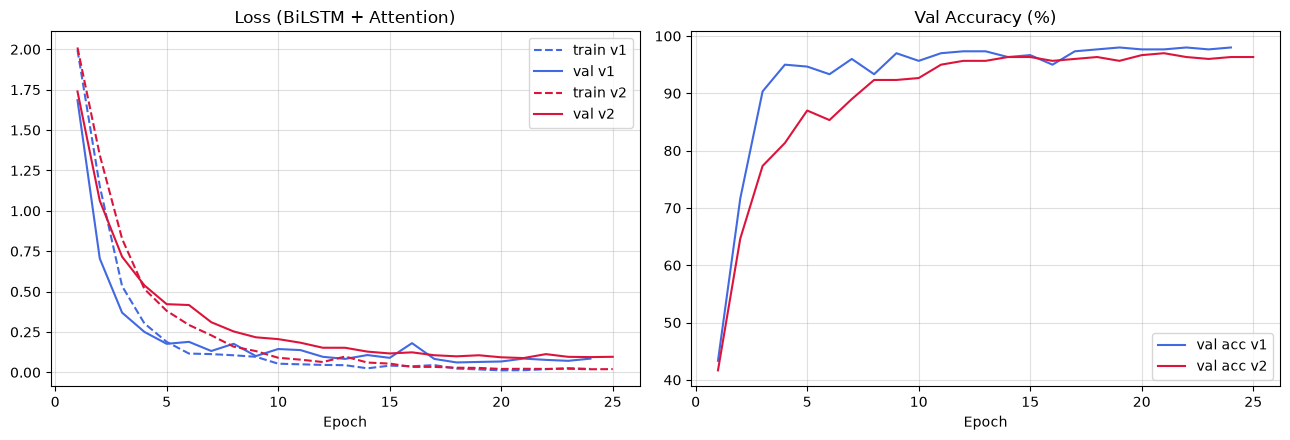

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ver, c in [('v1 (bằng chứng ở câu đầu)', 'royalblue'), ('v2 (vị trí ngẫu nhiên)', 'crimson')]:
    _, h = store[(ver, 0)]
    ep = range(1, len(h['train_loss']) + 1)
    axes[0].plot(ep, h['train_loss'], '--', color=c, label=f'train {ver[:2]}')
    axes[0].plot(ep, h['val_loss'], '-', color=c, label=f'val {ver[:2]}')
    axes[1].plot(ep, [a*100 for a in h['val_acc']], color=c, label=f'val acc {ver[:2]}')
axes[0].set_title('Loss (BiLSTM + Attention)'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(alpha=.4)
axes[1].set_title('Val Accuracy (%)'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(alpha=.4)
plt.tight_layout(); plt.savefig('results/attn_learning_curves.png', dpi=200); plt.show()